# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 (scratch) from random initial weights (no ImageNet pretraining), with the tuned hyperparameters in `ARCH_HYPERPARAMS["resnet18_scratch"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: CapeFlats
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["resnet18_scratch"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18 (scratch): micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18 (scratch): micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 32)
Train: 846 | Val: 205 | Test: 1476


## Model

In [3]:
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-18 (scratch)] Gradient accumulation: 2 micro-batches per optimizer step.


[ResNet-18 (scratch)] Epoch   1/100 | LR: 6.83e-05 | train loss 1.0699 acc 0.499 | val loss 0.8737 acc 0.644 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 6.83e-05 | train loss 0.9951 acc 0.585 | val loss 0.7944 acc 0.590 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 6.83e-05 | train loss 0.9234 acc 0.579 | val loss 0.7404 acc 0.712 *


[ResNet-18 (scratch)] Epoch   4/100 | LR: 6.83e-05 | train loss 0.8907 acc 0.592 | val loss 0.7974 acc 0.600


...

[ResNet-18 (scratch)] Epoch  42/100 | LR: 6.83e-06 | train loss 0.2635 acc 0.878 | val loss 0.4284 acc 0.815


[ResNet-18 (scratch)] Epoch  43/100 | LR: 6.83e-06 | train loss 0.2356 acc 0.885 | val loss 0.4451 acc 0.805


[ResNet-18 (scratch)] Epoch  44/100 | LR: 6.83e-06 | train loss 0.2272 acc 0.876 | val loss 0.3984 acc 0.834


[ResNet-18 (scratch)] Epoch  45/100 | LR: 6.83e-06 | train loss 0.2208 acc 0.895 | val loss 0.4305 acc 0.839


[ResNet-18 (scratch)] Epoch  46/100 | LR: 6.83e-06 | train loss 0.2053 acc 0.903 | val loss 0.4235 acc 0.824

[ResNet-18 (scratch)] No val loss improvement for 10 epochs, stopping at epoch 46.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.3873)


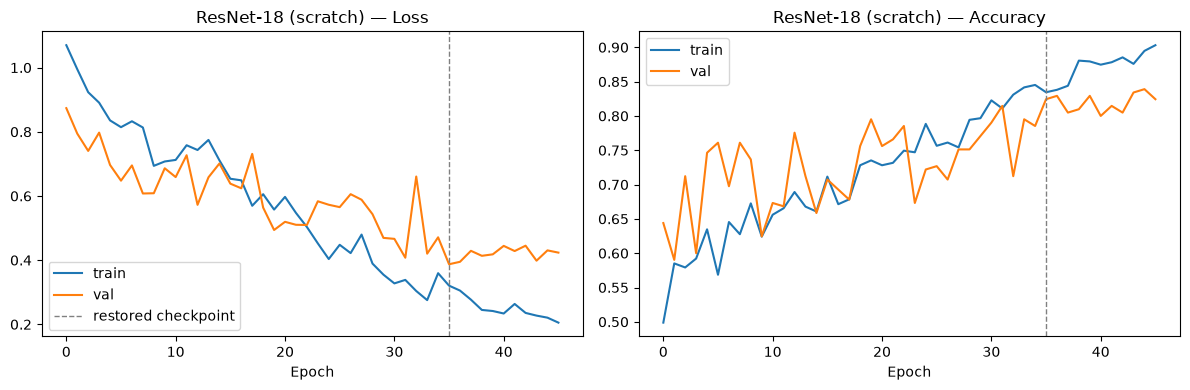

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.518


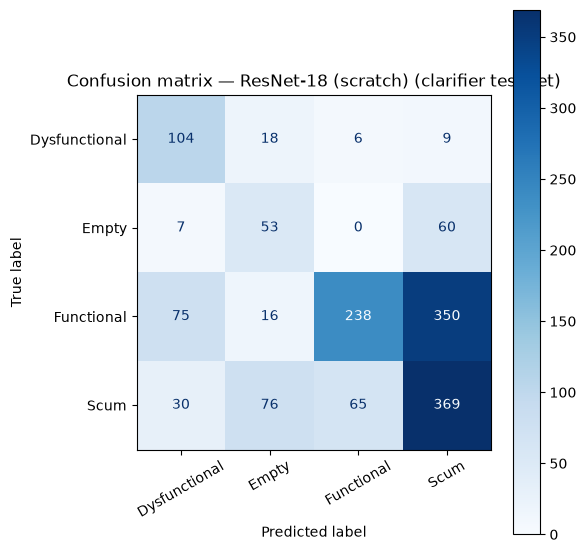

               precision    recall  f1-score   support

Dysfunctional      0.481     0.759     0.589       137
        Empty      0.325     0.442     0.375       120
   Functional      0.770     0.351     0.482       679
         Scum      0.468     0.683     0.556       540

     accuracy                          0.518      1476
    macro avg      0.511     0.559     0.500      1476
 weighted avg      0.597     0.518     0.510      1476



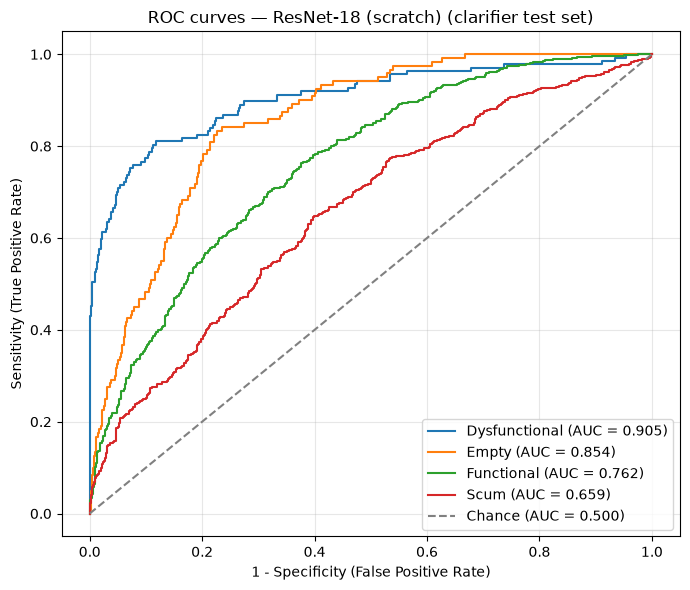

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.905
  Empty          : 0.854
  Functional     : 0.762
  Scum           : 0.659

Mean AUC (over 4/4 classes with test examples): 0.795


(np.float64(0.5176151761517616),
 {'Dysfunctional': 0.904629776006716,
  'Empty': 0.854037610619469,
  'Functional': 0.7619922278500192,
  'Scum': 0.659468977524533})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/clarifier_aug/results_clarifier_resnet18_scratch_CapeFlats.pkl
Saved model weights to ../models/pad/clarifier_aug/clarifier_resnet18_scratch_CapeFlats.pt
